In [1]:
# Mount Google Drive and Set Paths
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# Setup and load data

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set(style="whitegrid")

base_dir = Path("/content/drive/MyDrive/gdsc-drug-response")
data_path = base_dir / "processed" / "cisplatin_rnaseq_modelready.csv"

df = pd.read_csv(data_path)
df.shape
df.head()

,model_id,drug_name,ln_ic50,A1BG,A1BG-AS1,A1CF,A2M,A2M-AS1,A2ML1,A2ML1-AS1,...,ZXDA,ZXDB,ZXDC,ZYG11A,ZYG11AP1,ZYG11B,ZYX,ZYXP1,ZZEF1,ZZZ3
0,SIDM01132,Cisplatin,3.168266,5.18545,2.9833,0.0000,0.52325,0.0000,0.0213,0.0,...,0.31285,1.60475,3.10825,0.6801,0.0,2.58955,5.95435,0.0,3.47415,4.0301
1,SIDM00848,Cisplatin,-0.007561,4.86890,3.4476,0.0000,1.99640,0.1243,3.1890,0.0,...,1.68260,2.33060,5.18630,0.0841,0.0,3.09930,5.52420,NaN,3.60640,4.5211
2,SIDM00269,Cisplatin,0.045420,4.54970,3.8001,0.0841,3.21570,0.0566,0.5753,0.0,...,2.82980,3.41280,6.78270,2.3190,0.0,4.21410,9.01050,0.0,4.93400,5.4561
3,SIDM00203,Cisplatin,0.923136,4.22500,3.2095,0.0144,0.50590,0.0976,2.8156,0.0,...,2.49570,3.47640,5.30710,3.0321,0.0,4.47310,6.95290,0.0,4.35900,5.3366
4,SIDM01111,Cisplatin,-0.134330,4.49250,2.8115,0.0144,0.47510,0.0286,0.5558,0.0,...,1.28690,2.26000,4.94810,2.7634,0.0,3.20950,3.99550,NaN,4.02240,4.9635


In [3]:
# Define key columns:

model_col    = "model_id"
drug_col     = "drug_name"
response_col = "ln_ic50"

non_feature_cols = [model_col, drug_col, response_col]
feature_cols = [c for c in df.columns if c not in non_feature_cols]

len(feature_cols)

41143

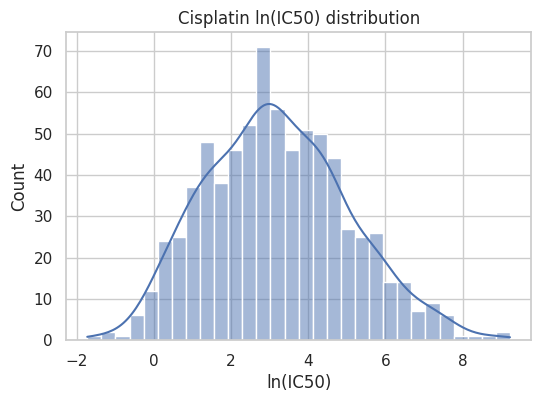

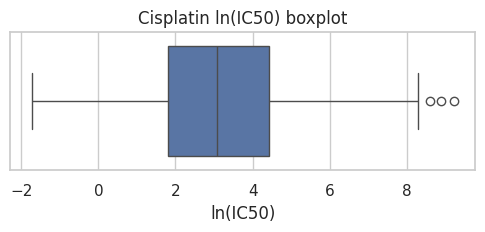

In [4]:
# Basic checks and summary of LN_IC50

df[[model_col, drug_col, response_col]].head()
df[response_col].describe()

plt.figure(figsize=(6,4))
sns.histplot(df[response_col], bins=30, kde=True)
plt.xlabel("ln(IC50)")
plt.title("Cisplatin ln(IC50) distribution")
plt.show()

plt.figure(figsize=(6,1.8))
sns.boxplot(x=df[response_col])
plt.xlabel("ln(IC50)")
plt.title("Cisplatin ln(IC50) boxplot")
plt.show()

Feature Space Overview

In [5]:
# Missingness:

missing_frac = df[feature_cols].isna().mean()
print("Max missing fraction:", missing_frac.max())

# How many genes have >50% missing?
(missing_frac > 0.5).sum()

Max missing fraction: 0.6069986541049798


np.int64(4705)

In [6]:
# Basic variance:

feature_var = df[feature_cols].var()
feature_var.sort_values(ascending=False).head(10)
feature_var.sort_values().head(10)

,0
MTRNR2L9,0.0
SNORD114-6,0.0
SNORD114-5,0.0
SNORD114-4,0.0
SNORD114-31,0.0
SNORD114-30,0.0
SNORD114-3,0.0
SNORD114-29,0.0
BTG4P1,0.0
MIR433,0.0


In [7]:
# Quick univariate correlation screen

np.random.seed(42)
sampled_genes = np.random.choice(feature_cols, size=1000, replace=False)

corrs = df[list(sampled_genes) + [response_col]].corr()[response_col].drop(response_col)
top_pos = corrs.sort_values(ascending=False).head(10)
top_neg = corrs.sort_values().head(10)

top_pos, top_neg

(WWC1        0.444481
 CTTN        0.414323
 KRT18P11    0.369071
 ELOVL1      0.363345
 SEC14L2     0.355411
 DKK1        0.343567
 PRRG2       0.342314
 ELOVL7      0.323690
 KIF3B       0.309777
 FOSL2       0.306935
 Name: ln_ic50, dtype: float64,
 IRAG2    -0.411404
 RPS28    -0.383305
 BTK      -0.376653
 NLRC3    -0.371475
 RPL18A   -0.365344
 TRGV4    -0.339829
 CD69     -0.337339
 ZGRF1    -0.336846
 MRPS31   -0.334288
 ZNF101   -0.334236
 Name: ln_ic50, dtype: float64)

In [8]:
# Save a lightly cleaned version

# Example: keep genes with at most 30% missing
keep_genes = missing_frac[missing_frac <= 0.3].index.tolist()
df_clean = df[non_feature_cols + keep_genes].copy()

clean_path = base_dir / "processed" / "cisplatin_rnaseq_modelready_clean.csv"
df_clean.to_csv(clean_path, index=False)
clean_path, df_clean.shape

(PosixPath('/content/drive/MyDrive/gdsc-drug-response/processed/cisplatin_rnaseq_modelready_clean.csv'),
 (743, 36441))